# 2. Install Library Tambahan


In [1]:
%pip install sentence-transformers gensim scikit-learn seaborn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# 3. Import Library


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sentence_transformers import SentenceTransformer

# 4. Load dataset

In [3]:
data = pd.read_csv("D:/NLP/Modul-2/review_gopay_newest_sort.csv")

# Memilih kolom content
text_column = "content"

data = data.dropna(subset=[text_column]).copy()
data[text_column] = data[text_column].astype(str).str.strip()
data = data[data[text_column] != ""]

# Mengambil 100 ulasan untuk praktikum
sample_texts = data[text_column].head(100).tolist()

print(f"Jumlah sample: {len(sample_texts)}")

for i, text in enumerate(sample_texts[:5], 1):
    print(f"{i}. {text}")

Jumlah sample: 100
1. Mantap
2. Bagus dan mudah digunakan
3. Good
4. Sangat membantu orang menengah mantap semoga sukses terus gopay
5. Ga ribet .. Sukaaaa


# 5. Demonstrasi Masalah Static Embedding

In [4]:
from gensim.models import Word2Vec

model_w2v = Word2Vec.load("../pertemuan-07/word2vec_model.bin")

ambiguous_sentences = [
    "ular itu berbisa mematikan",
    "saya bisa berenang jauh",
    "obat itu manjur bisa menyembuhkan"
]

print("Demonstrasi Keterbatasan Static Embedding:")
print("=" * 60)
print("Kata 'bisa' selalu memiliki vektor yang SAMA:")

if "bisa" in model_w2v.wv:
    vec = model_w2v.wv["bisa"]
    print(f"Vektor 'bisa' (10 dimensi pertama): {vec[:10].round(3)}")
else:
    print("Kata 'bisa' tidak ada dalam vocabulary model ini.")

Demonstrasi Keterbatasan Static Embedding:
Kata 'bisa' selalu memiliki vektor yang SAMA:
Vektor 'bisa' (10 dimensi pertama): [ 0.082 -0.097 -0.224 -0.573 -0.245  0.011  0.379  0.206 -0.46   0.003]


#  6. Load Sentence Transformer Model

In [5]:
# Model multilingual yang mendukung Bahasa Indonesia
model_st = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
print("Model Sentence Transformer berhasil dimuat.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model Sentence Transformer berhasil dimuat.


# 7. Menghasilkan Sentence Embedding

In [8]:
embeddings = model_st.encode(
    sample_texts,
    show_progress_bar=True,
    batch_size=8
)

print(f"Shape embeddings: {embeddings.shape}")
print(f"Dimensi per kalimat: {embeddings.shape[1]}")

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Shape embeddings: (100, 384)
Dimensi per kalimat: 384


# 8. Semantic Similarity antar Kalimat

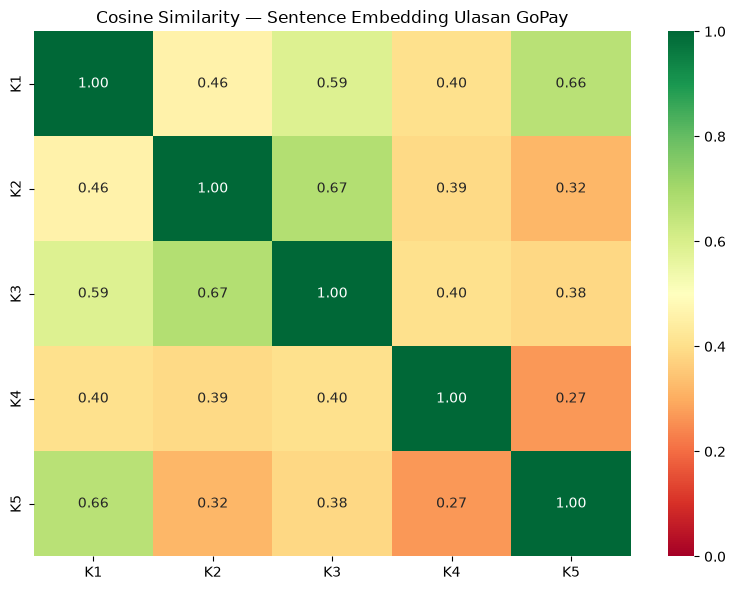

K1: Mantap
K2: Bagus dan mudah digunakan
K3: Good
K4: Sangat membantu orang menengah mantap semoga sukses terus gopay
K5: Ga ribet .. Sukaaaa


In [9]:
test_sentences = sample_texts[:5]
test_embeddings = model_st.encode(test_sentences)

sim_matrix = cosine_similarity(test_embeddings)

plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    xticklabels=[f"K{i+1}" for i in range(len(test_sentences))],
    yticklabels=[f"K{i+1}" for i in range(len(test_sentences))]
)

plt.title("Cosine Similarity — Sentence Embedding Ulasan GoPay")
plt.tight_layout()
plt.show()

for i, text in enumerate(test_sentences, 1):
    print(f"K{i}: {text[:120]}")

# 9. Demonstrasi Contextual Embedding

In [10]:
context_pairs = [
    (
        "Aplikasi GoPay memudahkan pembayaran.",
        "GoPay membantu saya melakukan pembayaran dengan praktis."
    ),
    (
        "Saldo GoPay saya bertambah setelah top up.",
        "Saldo GoPay saya berkurang setelah transaksi."
    ),
    (
        "Aplikasi GoPay berjalan lancar.",
        "Aplikasi GoPay sering mengalami error."
    )
]

print("Perbandingan Semantic Similarity Konteks Berbeda:")
print("=" * 60)

for s1, s2 in context_pairs:
    e1 = model_st.encode([s1])
    e2 = model_st.encode([s2])
    sim = cosine_similarity(e1, e2)[0][0]

    print(f"\nK1: {s1}")
    print(f"K2: {s2}")
    print(f"Similarity: {sim:.4f}")

Perbandingan Semantic Similarity Konteks Berbeda:

K1: Aplikasi GoPay memudahkan pembayaran.
K2: GoPay membantu saya melakukan pembayaran dengan praktis.
Similarity: 0.7790

K1: Saldo GoPay saya bertambah setelah top up.
K2: Saldo GoPay saya berkurang setelah transaksi.
Similarity: 0.4551

K1: Aplikasi GoPay berjalan lancar.
K2: Aplikasi GoPay sering mengalami error.
Similarity: 0.5510


# 10. Document Retrieval dengan Sentence Embedding

In [11]:
def semantic_search(query, corpus_embeddings, corpus_texts, top_n=5):
    query_embedding = model_st.encode([query])

    similarities = cosine_similarity(
        query_embedding,
        corpus_embeddings
    )[0]

    top_indices = similarities.argsort()[::-1][:top_n]

    results = []

    for idx in top_indices:
        results.append({
            "score": similarities[idx],
            "text": corpus_texts[idx]
        })

    return results


query = "aplikasi GoPay sering mengalami gangguan"
results = semantic_search(query, embeddings, sample_texts)

print(f"Query: '{query}'")
print("=" * 60)

for i, res in enumerate(results, 1):
    print(f"\n{i}. [Score: {res['score']:.4f}]")
    print(f"   {res['text'][:150]}")

Query: 'aplikasi GoPay sering mengalami gangguan'

1. [Score: 0.5886]
   Sekarang gopay SDH ada Goplay later SM Gopay pinjam, bebas transfer kapan saja, semoga kedepan pelayanan dari aplikasi ini lebih baik lagi.

2. [Score: 0.4634]
   aplikasi babi,mau isi pulsa Telkomsel ja gangguan asuu

3. [Score: 0.4613]
   Gopay memudahkan transaksi

4. [Score: 0.4585]
   Aplikasi ini gak guna ya

5. [Score: 0.4050]
   aplikasinya nyusahin. mau log in aja ribet. baru pertama kali log in udh dibilang terlalu banyak nomor hp yang dimasukkan kayak gojek.


# 11. Visualisasi Sentence Embedding dengan PCA

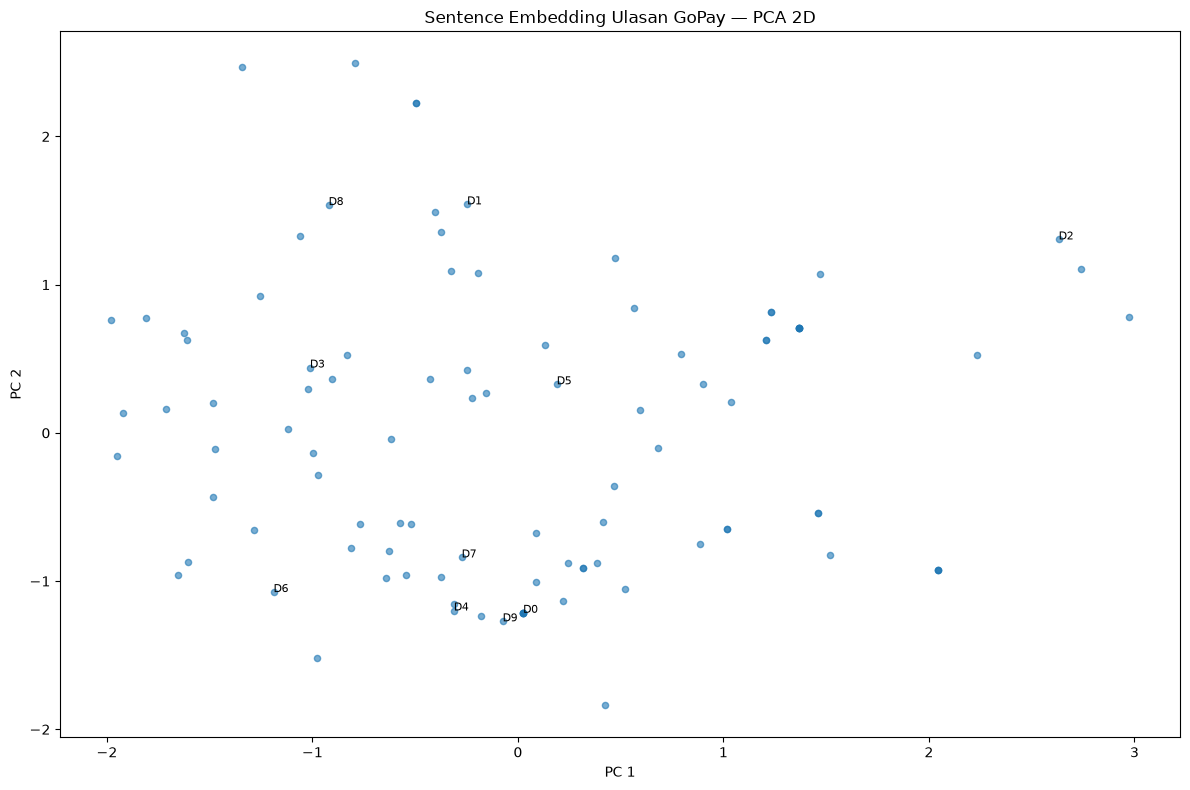

Variansi yang dijelaskan: 31.33%


In [12]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    alpha=0.6,
    s=20
)

for i in range(min(10, len(sample_texts))):
    plt.annotate(
        f"D{i}",
        xy=(embeddings_2d[i, 0], embeddings_2d[i, 1]),
        fontsize=8
    )

plt.title("Sentence Embedding Ulasan GoPay — PCA 2D")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

print(
    f"Variansi yang dijelaskan: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

# 12. Visualisasi dengan t-SNE

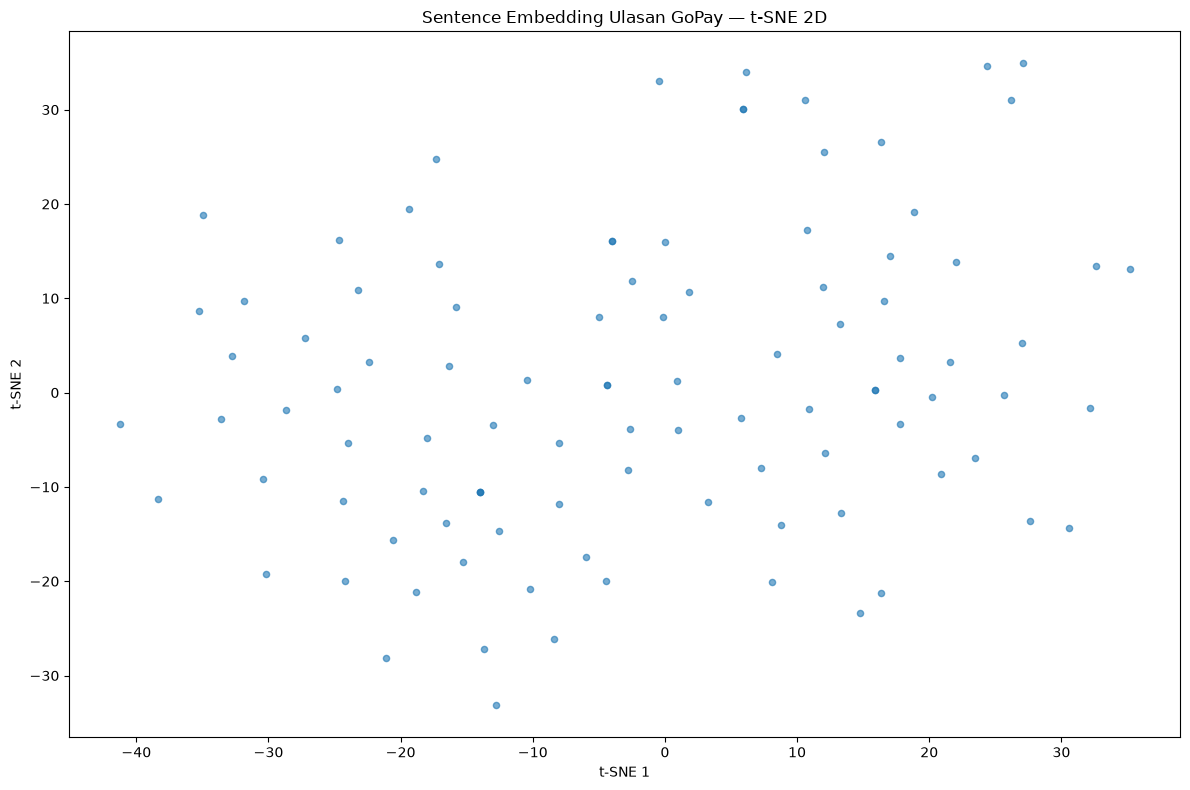

In [ ]:
perplexity_value = min(20, len(embeddings) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    random_state=42,
    max_iter=1000,
    init="pca",
    learning_rate="auto"
)

embeddings_tsne = tsne.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    alpha=0.6,
    s=20
)

plt.title("Sentence Embedding Ulasan GoPay — t-SNE 2D")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

# 13. Clustering Dokumen Berdasarkan Embedding

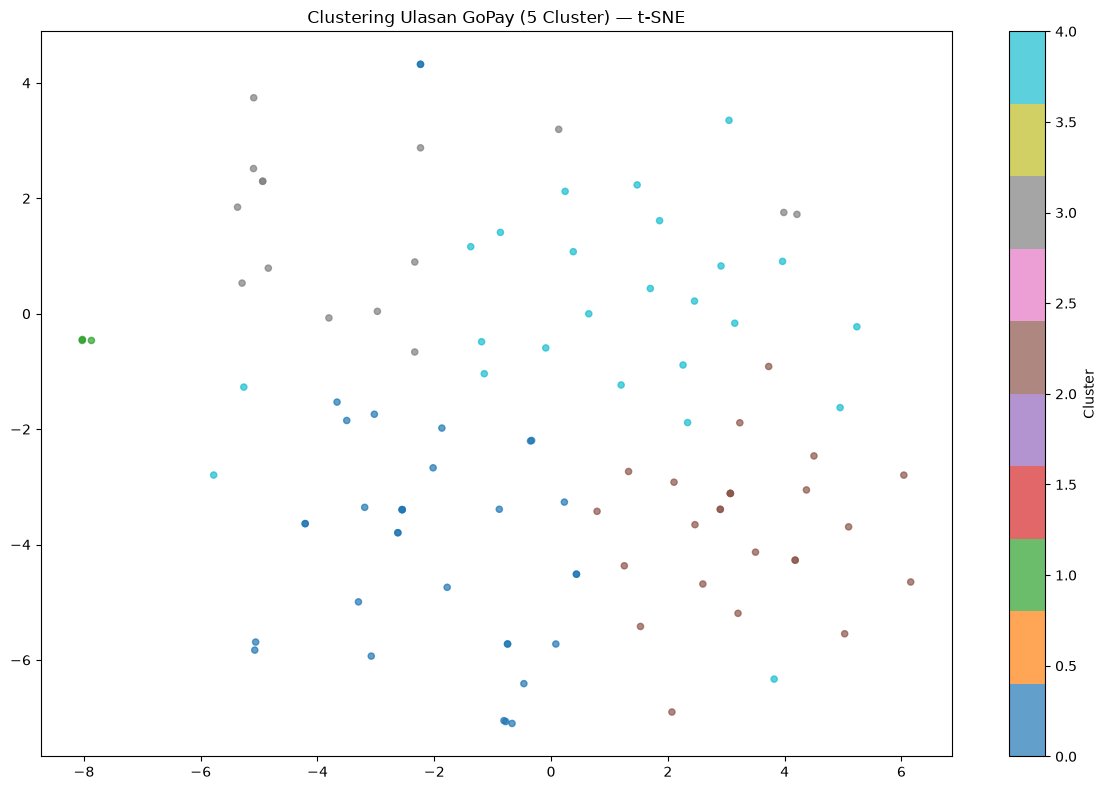


Cluster 0 (contoh ulasan):
- Good
- Sangat membantu
- keren, dan sangat terbantu

Cluster 1 (contoh ulasan):
- Sangat mudah
- Mudah dan sangat ringkas
- mudah dan cepat

Cluster 2 (contoh ulasan):
- Mantap
- Ga ribet .. Sukaaaa
- mantap mantap mantap

Cluster 3 (contoh ulasan):
- Bagus dan mudah digunakan
- Layanan sang Mudah Dan Sangat Memuaskan
- Bagus aplikasinya saya suka

Cluster 4 (contoh ulasan):
- Sangat membantu orang menengah mantap semoga sukses terus gopay
- Mantap pakay gopay
- Mohon di buka kembali goppy saya🙏🙏


In [14]:
from sklearn.manifold import TSNE

embeddings_tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, len(embeddings) - 1)
).fit_transform(embeddings)

n_clusters = min(5, len(embeddings))

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(embeddings)

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    c=cluster_labels,
    cmap="tab10",
    alpha=0.7,
    s=20
)

plt.colorbar(scatter, label="Cluster")
plt.title(f"Clustering Ulasan GoPay ({n_clusters} Cluster) — t-SNE")
plt.tight_layout()
plt.show()

for cluster_id in range(n_clusters):
    indices = np.where(cluster_labels == cluster_id)[0][:3]

    print(f"\nCluster {cluster_id} (contoh ulasan):")

    for idx in indices:
        print(f"- {sample_texts[idx][:120]}")

# F. Tugas Analisis

In [15]:
# NOMOR 1. Tiga pasang kalimat yang maknanya mirip

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

pasangan_mirip = [
    ("Aplikasi GoPay sangat mudah digunakan.",
     "GoPay gampang dipakai untuk transaksi."),
    
    ("Saldo GoPay saya berkurang sendiri.",
     "Saldo di GoPay tiba-tiba hilang."),
    
    ("Saya kesulitan melakukan pembayaran.",
     "Pembayaran menggunakan aplikasi gagal dilakukan.")
]

for i, (kalimat1, kalimat2) in enumerate(pasangan_mirip, start=1):
    vektor = model_st.encode([kalimat1, kalimat2])
    similarity = cosine_similarity(
        [vektor[0]], [vektor[1]]
    )[0][0]

    print(f"Pasangan {i}")
    print("Kalimat 1:", kalimat1)
    print("Kalimat 2:", kalimat2)
    print(f"Similarity: {similarity:.4f}\n")


Pasangan 1
Kalimat 1: Aplikasi GoPay sangat mudah digunakan.
Kalimat 2: GoPay gampang dipakai untuk transaksi.
Similarity: 0.8344

Pasangan 2
Kalimat 1: Saldo GoPay saya berkurang sendiri.
Kalimat 2: Saldo di GoPay tiba-tiba hilang.
Similarity: 0.6758

Pasangan 3
Kalimat 1: Saya kesulitan melakukan pembayaran.
Kalimat 2: Pembayaran menggunakan aplikasi gagal dilakukan.
Similarity: 0.4687



In [16]:
# NOMOR 2, Tiga pasang kalimat dengan kata sama tetapi makna berbeda

pasangan_berbeda = [
    ("Saya suka menggunakan GoPay.",
     "Saya tidak suka menggunakan GoPay."),
    
    ("Pembayaran berhasil dilakukan.",
     "Pembayaran tidak berhasil dilakukan."),
    
    ("Saldo saya bertambah setelah menerima uang.",
     "Saldo saya berkurang setelah melakukan transaksi.")
]

for i, (kalimat1, kalimat2) in enumerate(pasangan_berbeda, start=1):
    vektor = model_st.encode([kalimat1, kalimat2])
    similarity = cosine_similarity(
        [vektor[0]], [vektor[1]]
    )[0][0]

    print(f"Pasangan {i}")
    print("Kalimat 1:", kalimat1)
    print("Kalimat 2:", kalimat2)
    print(f"Similarity: {similarity:.4f}\n")


Pasangan 1
Kalimat 1: Saya suka menggunakan GoPay.
Kalimat 2: Saya tidak suka menggunakan GoPay.
Similarity: 0.4943

Pasangan 2
Kalimat 1: Pembayaran berhasil dilakukan.
Kalimat 2: Pembayaran tidak berhasil dilakukan.
Similarity: 0.4829

Pasangan 3
Kalimat 1: Saldo saya bertambah setelah menerima uang.
Kalimat 2: Saldo saya berkurang setelah melakukan transaksi.
Similarity: 0.5035



In [17]:
# NOMOR 3: Perbandingan Document Retrieval TF-IDF dan Sentence Transformer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Ambil maksimal 1.000 ulasan
dokumen = data["content"].dropna().astype(str).tolist()
dokumen = dokumen[:1000]

query = "saldo GoPay berkurang dan transaksi gagal"

# TF-IDF
tfidf = TfidfVectorizer()
matriks_tfidf = tfidf.fit_transform(dokumen)
vektor_query_tfidf = tfidf.transform([query])

skor_tfidf = cosine_similarity(
    vektor_query_tfidf, matriks_tfidf
).flatten()

hasil_tfidf = skor_tfidf.argsort()[-5:][::-1]

print("=== HASIL TF-IDF ===")
for indeks in hasil_tfidf:
    print(f"Skor: {skor_tfidf[indeks]:.4f}")
    print(dokumen[indeks], "\n")

# Sentence Transformer
vektor_query = model_st.encode([query])

vektor_dokumen = model_st.encode(
    dokumen,
    batch_size=32,
    show_progress_bar=True
)

skor_st = cosine_similarity(
    vektor_query, vektor_dokumen
).flatten()

hasil_st = skor_st.argsort()[-5:][::-1]

print("=== HASIL SENTENCE TRANSFORMER ===")
for indeks in hasil_st:
    print(f"Skor: {skor_st[indeks]:.4f}")
    print(dokumen[indeks], "\n")


=== HASIL TF-IDF ===
Skor: 0.4272
Mantap dan saldo aman, transaksi lancar jaya 

Skor: 0.3946
Gopay memudahkan transaksi 

Skor: 0.3029
pakai gopay lebih mudah transaksi 

Skor: 0.2865
Memudahkan transaksi 

Skor: 0.2756
akses transaksi cepat dan mudah. 



Batches:   0%|          | 0/32 [00:00<?, ?it/s]

=== HASIL SENTENCE TRANSFORMER ===
Skor: 0.7002
mengecewakan. transaksi not valid tapi saldo kepotong gak balik lagi. 

Skor: 0.6315
Sy baru pertama instal GoPay..dan tidak mengerti pembayaran GoBills ..pas tukar kode gagal trs 120.000 takut hangus.. Tolong donk min penjelasan dan kegunaan GoBills itu apa 

Skor: 0.6076
GoPay mempermudah transaksi baik belanja atau transfer ke bank konvensional 

Skor: 0.5732
Gopay sudah tidak lagi prioritaskan penggunanya,keluhan gopay later saya ga bisa dipakai sama sekali,management buruk dari bulan 6 ke 7 - 2024.Sangat mengecewakan pengguna aktiv.Iya moga aja bisa kembali 

Skor: 0.5634
Kenapa ya saldonya langsung hilang 



In [18]:
# NOMOR 4, Analisis cluster yang terbentuk

from sklearn.cluster import KMeans
from collections import Counter

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

label_cluster = kmeans.fit_predict(embeddings)

for nomor_cluster in range(3):
    anggota = [
        sample_texts[i]
        for i in range(len(sample_texts))
        if label_cluster[i] == nomor_cluster
    ]

    print(f"\n=== CLUSTER {nomor_cluster} ===")
    print("Jumlah dokumen:", len(anggota))

    for ulasan in anggota[:5]:
        print("-", ulasan)



=== CLUSTER 0 ===
Jumlah dokumen: 32
- Good
- Sangat membantu
- keren, dan sangat terbantu
- Baik dan bersahabat
- Sangat baik

=== CLUSTER 1 ===
Jumlah dokumen: 33
- Mantap
- Ga ribet .. Sukaaaa
- Mantap pakay gopay
- mantap mantap mantap
- Berbisnis

=== CLUSTER 2 ===
Jumlah dokumen: 35
- Bagus dan mudah digunakan
- Sangat membantu orang menengah mantap semoga sukses terus gopay
- Layanan sang Mudah Dan Sangat Memuaskan
- Sangat mudah
- Gopay yang sangat mantap respon cepat


# G. Pertanyaan Diskusi

1. Apa perbedaan mendasar antara static embedding dan contextual embedding?

Static embedding memberikan representasi vektor yang sama untuk kata yang sama, meskipun digunakan dalam kalimat berbeda. Sementara itu, contextual embedding menghasilkan representasi berdasarkan konteks kalimat sehingga makna kata dapat dibedakan sesuai penggunaannya.

2. Bagaimana model Sentence Transformer menghasilkan representasi kalimat yang berbeda untuk kata yang sama?

Sentence Transformer memproses kalimat secara keseluruhan untuk menghasilkan representasi vektor yang menggambarkan maknanya. Konteks kata dalam kalimat membantu model membedakan makna, meskipun kata yang digunakan sama.

3. Mengapa contextual embedding sangat berguna untuk task NLP modern?

Contextual embedding berguna karena dapat menangkap makna kata berdasarkan konteksnya. Hal ini membantu tugas NLP seperti analisis sentimen, pencarian dokumen, klasifikasi teks, dan pengukuran kemiripan kalimat.

4. Apa trade-off antara efisiensi komputasi dan kualitas embedding?

Model yang lebih besar biasanya membutuhkan lebih banyak memori dan waktu pemrosesan, tetapi dapat menghasilkan representasi yang lebih baik untuk tugas tertentu. Sebaliknya, model yang lebih kecil lebih cepat dan hemat sumber daya, tetapi kualitas hasilnya bisa lebih rendah.

5. Bagaimana BERT menghasilkan contextual embedding?

BERT menggunakan mekanisme self-attention dua arah untuk memahami hubungan antarkata dalam sebuah kalimat. BERT memperhatikan konteks dari arah kiri dan kanan sehingga representasi suatu kata dapat berbeda sesuai dengan konteks penggunaannya.
